# Pump depletion and phase mismatch in a lossless crystal

Change the mismatch and step size. Inspect harmonic output and the conserved power separately. At exact phase matching compare the entire returned curve with the analytic hyperbolic-tangent solution.

Run this cell with OneSimulation, NumPy and Matplotlib installed. Adjust the parameters and rerun to compare with the reference output below.


Mismatch 0: harmonic fraction at z=3 = 0.99013
Max energy residual = 5.36e-11
Mismatch 2: harmonic fraction at z=3 = 0.38128
Max energy residual = 3.68e-10
Mismatch 6: harmonic fraction at z=3 = 0.01833
Max energy residual = 6.10e-10


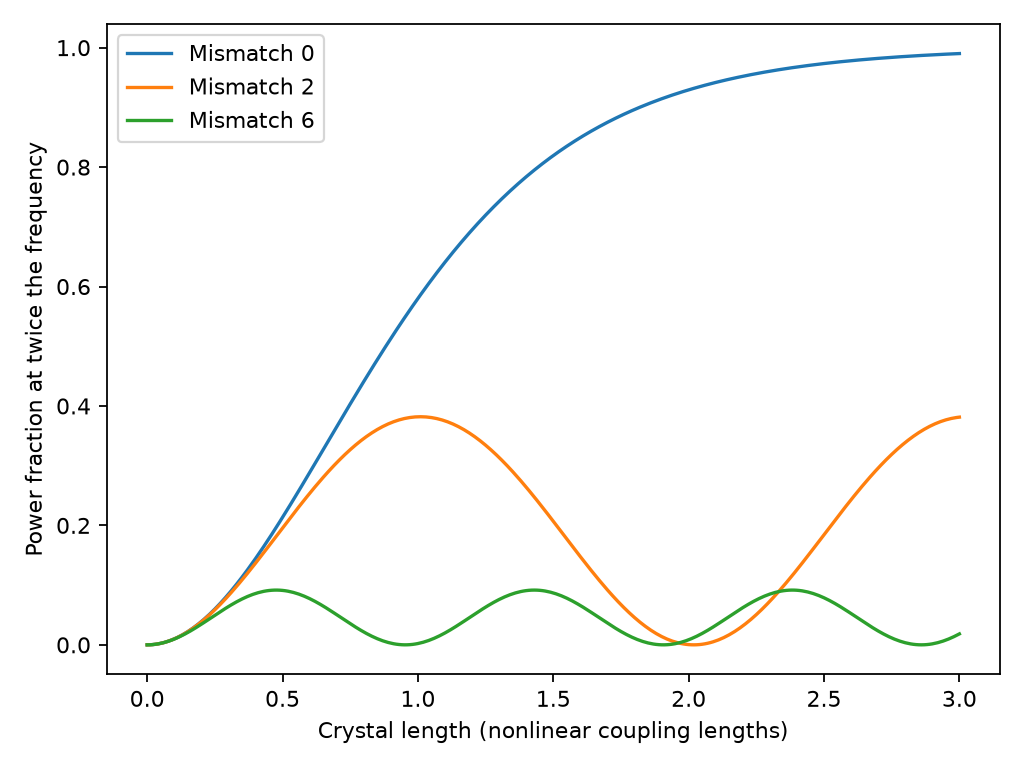

In [1]:
"""Normalised fundamental and second-harmonic envelopes in a lossless crystal."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.time import ClassicalRungeKutta4TimeIntegrator

def propagate(mismatch, step, count):
    def rates(state, z):
        a, b = complex(*state[:2]), complex(*state[2:])
        phase = np.exp(1j*mismatch*z)
        da = -a.conjugate()*b/phase
        db = a*a*phase
        return da.real, da.imag, db.real, db.imag
    method = ClassicalRungeKutta4TimeIntegrator()
    state = (1., 0., 0., 0.)
    trajectory = [state]
    for i in range(count):
        state = method.advance(state, rates, step, time=i*step)
        trajectory.append(state)
    ar, ai, br, bi = np.array(trajectory).T
    return ar**2+ai**2, br**2+bi**2

z = np.linspace(0, 3, 301)
for mismatch in (0., 2., 6.):
    pump, harmonic = propagate(mismatch, .01, 300)
    print(f"Mismatch {mismatch:g}: harmonic fraction at z=3 = {harmonic[-1]:.5f}")
    print(f"Max energy residual = {max(abs(pump+harmonic-1)):.2e}")
    plt.plot(z, harmonic, label=f"Mismatch {mismatch:g}")
    if mismatch == 0:
        assert np.max(abs(harmonic-np.tanh(z)**2)) < 1e-7
plt.xlabel("Crystal length (nonlinear coupling lengths)")
plt.ylabel("Power fraction at twice the frequency")
plt.legend()
plt.tight_layout()
plt.savefig("physics-harmonic-generation.png", dpi=160)

plt.show()
